<a href="https://colab.research.google.com/github/moyan-li/MSSP607/blob/main/Assignments/Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import drive
drive.mount('/content/drive')
from google.colab import userdata
import os

github_token = userdata.get('Key1')
owner = 'moyan-li' # Replace with the GitHub repository owner
repository = 'MSSP607' # Replace with the GitHub repository name

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
!git clone {clone_url}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
fatal: destination path 'MSSP607' already exists and is not an empty directory.



annual_sales
            Sales  Orders      Start        End
Year                                           
2010     43421.04      14 2010-12-29 2010-12-31
2011   7075525.93    2216 2011-01-01 2011-12-31
2012   5842485.20    3269 2012-01-01 2012-12-31
2013  16351550.34   21289 2013-01-01 2013-12-31
2014     45694.72     871 2014-01-01 2014-01-28

country_year_sales
Year                          2010        2011        2012        2013      2014
EnglishCountryRegionName                                                        
Australia                 20909.78  2563732.25  2128407.46  4339443.38   8507.72
Canada                     3578.27   571571.80   307604.52  1085632.65   9457.62
France                     3399.99   410845.33   648065.54  1578511.80   3195.06
Germany                       0.00   520500.16   608657.98  1761876.36   3277.83
United Kingdom              699.10   550591.22   712700.96  2124007.29   3713.64
United States             14833.90  2458285.17  1437048.73  546

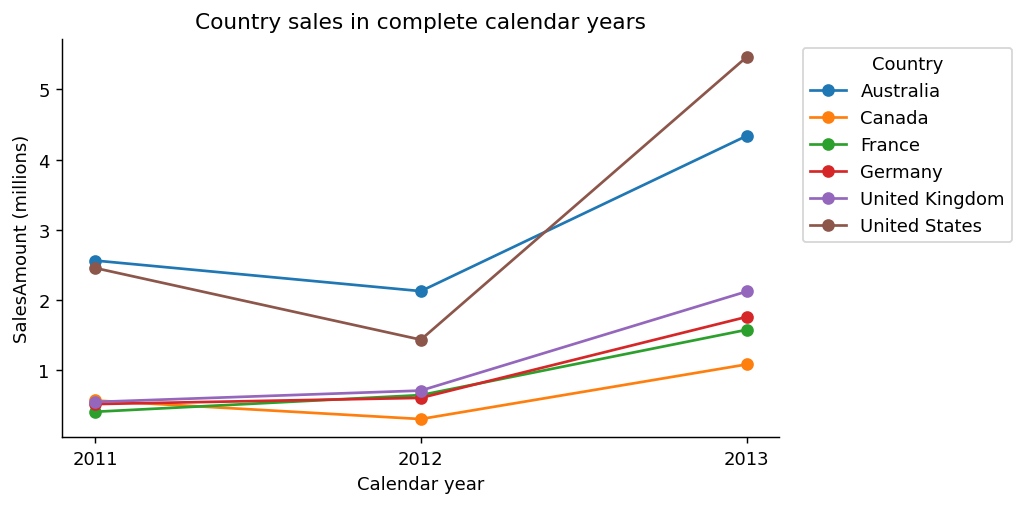

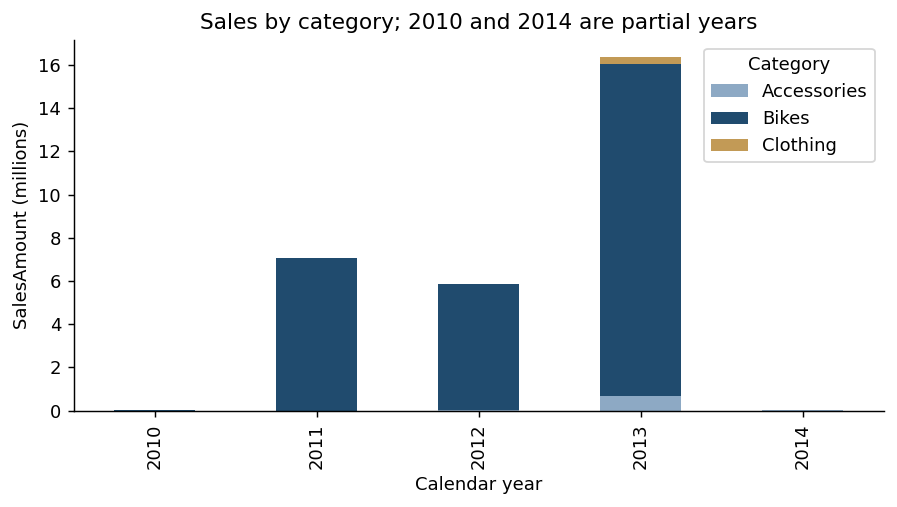

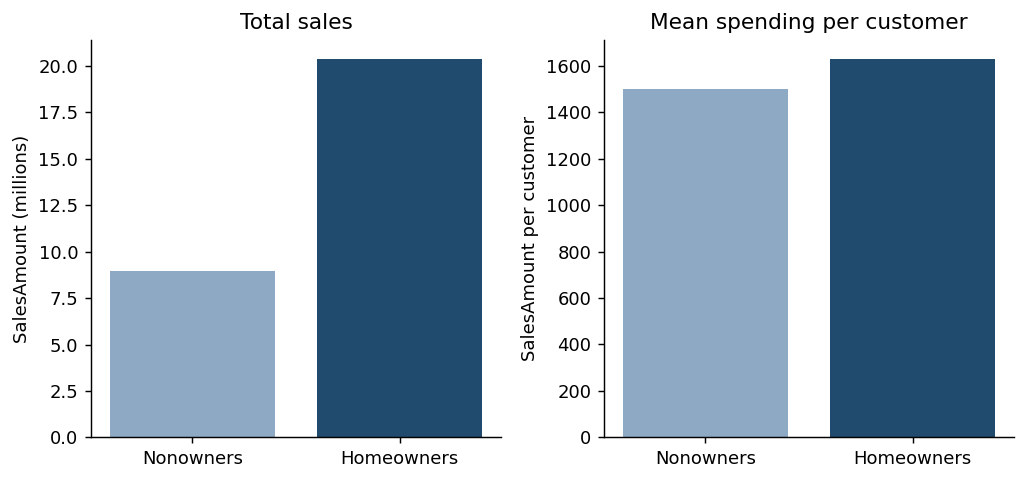

'/content/analysis_outputs.zip'

In [6]:
# Adventure Works Internet Sales analysis
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


INPUT = Path('/content/MSSP607/WeeklyModules/Week08/InternetSales.csv')
OUT = Path('analysis_outputs')
OUT.mkdir(exist_ok=True)
df = pd.read_csv(INPUT, encoding='cp1252', low_memory=False)
required = ['CustomerKey','EnglishCountryRegionName','Gender','YearlyIncome',
            'HouseOwnerFlag','SalesOrderNumber','SalesOrderLineNumber',
            'EnglishProductName','OrderQuantity','UnitPrice','SalesAmount',
            'TotalProductCost','OrderDate']
assert set(required).issubset(df.columns)
assert not df[required].isna().any().any(), 'Review missing required values before analysis.'
assert not df.duplicated(['SalesOrderNumber','SalesOrderLineNumber']).any(), 'Review repeated order lines.'
df['Date'] = pd.to_datetime(df['OrderDate'], format='%m/%d/%Y', errors='raise')
df['Year'] = df.Date.dt.year

# The file has no category field. This explicit mapping covers all observed names.
def classify(name):
    if name.startswith(('Mountain-', 'Road-', 'Touring-')):
        return 'Bikes'
    if name.startswith(('Short-Sleeve Classic Jersey', 'Long-Sleeve Logo Jersey',
                         'AWC Logo Cap', 'Half-Finger Gloves', 'Racing Socks',
                         "Women's Mountain Shorts", 'Classic Vest')):
        return 'Clothing'
    accessories = ['Fender Set - Mountain','Touring Tire','Touring Tire Tube',
        'Sport-100 Helmet, Red','Sport-100 Helmet, Black','Sport-100 Helmet, Blue',
        'Water Bottle - 30 oz.','Mountain Bottle Cage','Road Bottle Cage',
        'Patch Kit/8 Patches','HL Mountain Tire','Mountain Tire Tube','Road Tire Tube',
        'All-Purpose Bike Stand','ML Road Tire','Hitch Rack - 4-Bike','LL Mountain Tire',
        'ML Mountain Tire','LL Road Tire','Hydration Pack - 70 oz.','Bike Wash - Dissolver','HL Road Tire']
    if name in accessories:
        return 'Accessories'
    raise ValueError('Unmapped product: ' + name)
df['Category'] = df.EnglishProductName.map(classify)
df[['ProductKey','EnglishProductName','Category']].drop_duplicates().to_csv(OUT/'product_mapping.csv', index=False)


# Customer attributes are stable within this file; avoid weighting frequent buyers more.
attrs = ['EnglishCountryRegionName','Gender','YearlyIncome','HouseOwnerFlag']
assert df.groupby('CustomerKey')[attrs].nunique(dropna=False).le(1).all().all()
customers = df[['CustomerKey'] + attrs].drop_duplicates('CustomerKey').set_index('CustomerKey')
customers = customers.join(df.groupby('CustomerKey').SalesAmount.sum().rename('CustomerSales'))
annual = df.groupby('Year').agg(Sales=('SalesAmount','sum'),Orders=('SalesOrderNumber','nunique'),
                               Start=('Date','min'),End=('Date','max'))
country = df.pivot_table(index='EnglishCountryRegionName',columns='Year',values='SalesAmount',aggfunc='sum',fill_value=0)
income = customers.groupby(['EnglishCountryRegionName','Gender']).YearlyIncome.agg(['count','mean','min','max','std']) # sample SD, ddof=1
category = df.groupby('Category').agg(Sales=('SalesAmount','sum'),Units=('OrderQuantity','sum'),
                                     MeanUnitPrice=('UnitPrice','mean'),ProductCost=('TotalProductCost','sum'))
category['SalesSharePct'] = category.Sales / category.Sales.sum() * 100
category['WeightedUnitPrice'] = (df.assign(Value=df.UnitPrice*df.OrderQuantity).groupby('Category').Value.sum()/category.Units)
category['ProductMargin'] = category.Sales-category.ProductCost
by_year = df.pivot_table(index='Year',columns='Category',values='SalesAmount',aggfunc='sum',fill_value=0)
home = customers.groupby('HouseOwnerFlag').agg(Customers=('CustomerSales','size'),Sales=('CustomerSales','sum'),
                                            MeanCustomerSales=('CustomerSales','mean'),MedianCustomerSales=('CustomerSales','median'))


# Within-country comparison is descriptive and does not establish causation.
home_country = customers.groupby(['EnglishCountryRegionName','HouseOwnerFlag']).CustomerSales.agg(['count','mean','median'])
for name, table in {'annual_sales':annual,'country_year_sales':country,'income_country_gender':income,
                    'category_summary':category,'category_year_sales':by_year,'homeownership':home,
                    'homeownership_by_country':home_country}.items():
    print('\n'+name+'\n'+table.round(2).to_string())
    table.to_csv(OUT/(name+'.csv'))
print('\nRows:',len(df),'Customers:',len(customers),'Orders:',df.SalesOrderNumber.nunique())
print('Total sales:',df.SalesAmount.sum())
print('Currency keys:',df.CurrencyKey.unique())
print('2012 vs 2011:',annual.loc[2012,'Sales']/annual.loc[2011,'Sales']-1)
print('2013 vs 2012:',annual.loc[2013,'Sales']/annual.loc[2012,'Sales']-1)
print('Owner mean premium:',home.loc[1,'MeanCustomerSales']/home.loc[0,'MeanCustomerSales']-1)


# SalesAmount is aggregated as supplied. Currency normalization is an assumption,
# because multiple CurrencyKey values exist and no exchange-rate table is supplied.
plt.rcParams.update({'figure.dpi':130,'axes.spines.top':False,'axes.spines.right':False})
def save(fig, name):
    fig.tight_layout(); fig.savefig(OUT/name,dpi=220,bbox_inches='tight'); plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(8,4))
(country[[2011,2012,2013]].T/1e6).plot(marker='o',ax=ax)
ax.set(xlabel='Calendar year',ylabel='SalesAmount (millions)',title='Country sales in complete calendar years')
ax.set_xticks([2011,2012,2013]); ax.legend(title='Country',bbox_to_anchor=(1.02,1),loc='upper left')
save(fig,'A1_country_sales.png')
fig, ax = plt.subplots(figsize=(7,4))
(by_year/1e6).plot.bar(stacked=True,ax=ax,color=['#8da9c4','#204b6e','#c29a56'])
ax.set(xlabel='Calendar year',ylabel='SalesAmount (millions)',title='Sales by category; 2010 and 2014 are partial years')
save(fig,'A2_category_year_sales.png')
fig, axes = plt.subplots(1,2,figsize=(8,3.8))
labels=['Nonowners','Homeowners']
axes[0].bar(labels,home.Sales/1e6,color=['#8da9c4','#204b6e']);axes[0].set(title='Total sales',ylabel='SalesAmount (millions)')
axes[1].bar(labels,home.MeanCustomerSales,color=['#8da9c4','#204b6e']);axes[1].set(title='Mean spending per customer',ylabel='SalesAmount per customer')
save(fig,'A3_homeownership.png')

import shutil
shutil.make_archive('analysis_outputs','zip',OUT)

